# Lab 1 — Preprocessing a French Corpus

**Natural Language Processing** — Master's in Data Science & AI — ECE Paris

**Authors:** _Name 1_, _Name 2_

Goal: clean the Allociné reviews with regular expressions, tokenize and lemmatize them with spaCy, build a stop-word list that keeps negations, and describe the corpus (Zipf, hapaxes).

Deliverables: this notebook, `preprocess.py` and `test_preprocess.py` (written in Exercise 5).

## Setup

In [1]:
!pip install -q datasets spacy nltk matplotlib pytest
!python -m spacy download fr_core_news_sm

import re, unicodedata, time
from collections import Counter
import numpy as np
import pandas as pd, matplotlib.pyplot as plt
from datasets import load_dataset
import spacy, nltk
import warnings
warnings.filterwarnings("ignore", message="This pattern is interpreted as a regular expression")

     ---------------------------------------- 0.0/16.3 MB ? eta -:--:--
     ------------------------- ------------- 10.7/16.3 MB 56.1 MB/s eta 0:00:01
     ---------------------------------------- 16.3/16.3 MB 51.3 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_sm')


c:\Users\maxih\OneDrive\Skrivbord\skola\årskurs5\frankrike\nlp\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Exercise 1 — Load and inspect

In [2]:
ds = load_dataset("tblard/allocine")
print(ds)
df = ds["train"].shuffle(seed=42).select(range(2000)).to_pandas()
df.head()


DatasetDict({
    train: Dataset({
        features: ['review', 'label'],
        num_rows: 160000
    })
    validation: Dataset({
        features: ['review', 'label'],
        num_rows: 20000
    })
    test: Dataset({
        features: ['review', 'label'],
        num_rows: 20000
    })
})


,review,label
0,Ray Milland qui a tourné dans presque 200 film...,0
1,le film est très mauvais car : trop peu d'acti...,0
2,aie aie aie! En corse ça passait encore! Mais ...,0
3,Encore un film iranien. Au fil des films qui a...,1
4,Je ne me lancerai pas dans une analyse fine su...,0


### Q1.1 — Ten full reviews and their flaws

> Display 10 full reviews. Note at least three “flaws” in the raw text (tags, repetitions, typos, emojis…).

In [26]:
# Show 10 FULL reviews (no truncation)
pd.set_option("display.max_colwidth", None)
for i, row in df.head(10).iterrows():
    print(f"--- #{i} | label={row['label']} ({'pos' if row['label'] else 'neg'}) ---")
    print(row["review"])
    print()

--- #0 | label=0 (neg) ---
Ray Milland qui a tourné dans presque 200 films s'est amusé à en réaliser 5.Celui est est le plus connu mais pas le meilleur. Il y a certes quelques séquences réussies mais beaucoup trop qui semblent fabriquées ,les comédiens manquent d'aisance et l'acteur lui même qui sait être excellent avec Hitchcock,Lang,Wilder, et surtout Farrow (the big clock-1948) a du mal à se diriger lui même. L'ambiance est ce qu'il y a de mieux .Imaginer une guerre atomique sans la voir était un pari réussi mais la volonté de trop montrer le mauvais coté de la nature humaine est bien trop excessive et démonstrative. Le contre exemple représenté par la femme du héros finit par agacer. D'autre part,un petit peu plus et nous étions dans un film d'horreur ,ce qui n'était pas le propos .A l'évidence Milland avait d'autres ambitions mais elles ne furent pas tenues. Le film a vieilli ,ce qui n'est jamais bon ,alors qu'avec plus de talent cinématographique il pourrait être encore précurseu

In [4]:
# How frequent is each kind of noise in the whole 2,000-review sample?
patterns = {
    "HTML tag": r"<[^>]+>",
    "URL": r"https?://|www\.",
    "@mention / #hashtag": r"(?<!\w)[@#]\w+",
    "char repeated 3+ times": r"([^\d\s])\1{2,}",
    "'!!!' or '???'": r"([!?])\1{2,}",
    "missing space after punctuation": r"[a-zé][.,;!?][A-Za-zÉ]",
    "curly apostrophe ’": r"’",
    "emoji": r"[\U0001F300-\U0001FAFF\u2600-\u27BF]",
}
pd.DataFrame(
    [(name, df["review"].str.contains(p).sum()) for name, p in patterns.items()],
    columns=["flaw", "reviews containing it"],
)

,flaw,reviews containing it
0,HTML tag,0
1,URL,10
2,@mention / #hashtag,1
3,char repeated 3+ times,559
4,'!!!' or '???',88
5,missing space after punctuation,125
6,curly apostrophe ’,254
7,emoji,4


**Flaws observed in the raw text:**

1. **Missing or misplaced spaces around punctuation.** Examples: `5.Celui`, `Hitchcock,Lang,Wilder`, `fabriquées ,les` (#0) and `Besson.Une`, `1985(musique,looks)` (#6). A whitespace split glues these words together.
2. **Typos, missing accents and repeated words.** Examples: `Celui est est` (#0), `geniale`, `deconseile`, `malheuresement` (#1), `meme`, `agacante` (#6), `rafiné` (#5), `peche` (#8). Each misspelling becomes a separate, rare word type.
3. **Repeated characters.** Examples: ellipses `...` (#4, #7) and `aie aie aie!` (#2). In the whole sample, 559 reviews contain a character repeated 3+ times and 88 contain `!!!` or `???`.
4. **Two kinds of apostrophe.** `l'univers` uses a straight `'` and `l’état`, `n’aspire` (#3) use a curly `’`. Without normalization, `n'` and `n’` are different tokens. 254 reviews use `’`.
5. **Other noise.** There are explicit ratings (`4 étoiles`, #3), English words and titles (`the big clock-1948`, `free fight underground`, `April Snow`), informal text with no capitals or punctuation (#1), and a few URLs and emojis. No HTML tags appear in this sample, but `clean_text` still handles them in case other data has them.

### Q1.2 — Review length

> Compute the mean, median and maximum length of the reviews, in characters and then in words (split on whitespace).

In [5]:
df["n_chars"] = df["review"].str.len()
df["n_words"] = df["review"].str.split().str.len()

print(df[["n_chars", "n_words"]].agg(["mean", "median", "max"]).round(1))

        n_chars  n_words
mean      539.3     90.9
median    381.0     64.5
max      1998.0    353.0


Reviews are about **539 characters / 91 words** on average, with a median of **381 characters / 64.5 words** and a maximum of **1,998 characters / 353 words**. The mean is well above the median, so the distribution is right-skewed: most reviews are short and a few long ones pull the mean up. The maximum sits just under 2,000 characters, which suggests the reviews were capped at that length when the dataset was built.

### Q1.3 — Class distribution

> Display the class distribution (0 = negative, 1 = positive). Is the corpus balanced? Why does this matter for what follows?

label
0    1007
1     993
Name: count, dtype: int64
label
0    0.503
1    0.496
Name: proportion, dtype: float64


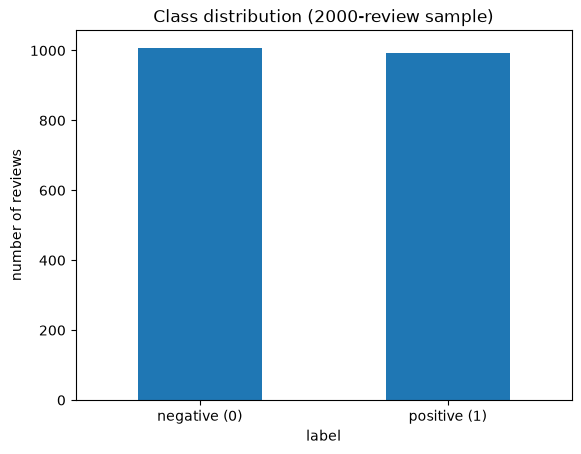

In [6]:
counts = df["label"].value_counts().sort_index()
print(counts)
print(df["label"].value_counts(normalize=True).sort_index().round(3))

counts.plot(kind="bar")
plt.xticks([0, 1], ["negative (0)", "positive (1)"], rotation=0)
plt.ylabel("number of reviews")
plt.title("Class distribution (2000-review sample)")
plt.show()

The corpus is balanced: 1007 negative reviews (50.3%) and 993 positive ones (49.7%). The 14-review gap is what random sampling from a 50/50 dataset produces. This matters because accuracy is then a reliable metric, with a random or majority-class baseline of about 50%. We don’t need resampling or class weights. Any model that scores clearly above 50% has learned something real. We should still use a stratified split to keep this ratio in the train and test sets.

## Exercise 2 — Clean with regular expressions

### Q2.1 — Complete `clean_text`

> Complete the four TODOs and check the output on the three test sentences.

In [7]:
def clean_text(text: str) -> str:
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)   # URLs
    text = re.sub(r"<[^>]+>", " ", text)                  # TODO 1: HTML tags
    text = re.sub(r"[@#]\w+", " ", text)                  # TODO 2: mentions / hashtags
    text = re.sub(r"([^\d\s])\1{2,}", r"\1", text)        # TODO 3: 3+ repeated chars -> 1
    text = re.sub(r"\s+", " ", text)                      # TODO 4: multiple spaces -> 1
    return text.strip()


tests = ["Génial !!!!! Voir https://ex.fr/film #cinema @marie",
         "<br />Trooop bien,   vraiment<br />",
         "Nul... je me suis ennuyé"]
for x in tests:
    print(repr(clean_text(x)))


'Génial ! Voir'
'Trop bien, vraiment'
'Nul. je me suis ennuyé'


All three test sentences come out as expected: the URL, hashtag, mention and `<br />` tags are gone, `!!!!!` becomes `!`, `Trooop` becomes `Trop`, and extra spaces are collapsed.

Choices made:
- HTML tags are replaced by a space, not by nothing, so `mot<br />mot` does not become one word.
- The repetition rule `([^\d\s])\1{2,}` skips digits, so numbers like `1000` or `2000` are not damaged.
- One side effect: the ellipsis `...` becomes `.` (see `Nul. je me suis ennuyé`), so it now looks like a normal sentence end.

### Q2.2 — Apply to the whole sample

> Apply clean_text to the whole sample (column review_clean). Show 3 reviews before / after.

In [8]:
df["review_clean"] = df["review"].apply(clean_text)
print(df.columns.tolist())   # should show 'review_clean'

changed = df[df["review"] != df["review_clean"]]
print(f"{len(changed)} / {len(df)} reviews modified")

for i, row in changed.sample(3, random_state=0).iterrows():
    print("BEFORE:", row["review"])
    print("AFTER :", row["review_clean"])
    print()

['review', 'label', 'n_chars', 'n_words', 'review_clean']
566 / 2000 reviews modified
BEFORE: hahahaahah une sombre bouse... samuel le bihan a vraiment le don pour gacher tous les films qu'il fait il merite bien l'oscar du pire jeu d'acteur juste devant christian clavier... circulez y'a rien a voir
AFTER : hahahaahah une sombre bouse. samuel le bihan a vraiment le don pour gacher tous les films qu'il fait il merite bien l'oscar du pire jeu d'acteur juste devant christian clavier. circulez y'a rien a voir

BEFORE: Je me suis laissé tenté par ce film diffusé sur Arte mais... c'est une vrai daube, intrigue confuse et sans véritable intérêt, jeu d'acteur lamentable, invraisemblances et anachronisme, bref du grand n'importe quoi ! Grotesque : un vrai nanar !
AFTER : Je me suis laissé tenté par ce film diffusé sur Arte mais. c'est une vrai daube, intrigue confuse et sans véritable intérêt, jeu d'acteur lamentable, invraisemblances et anachronisme, bref du grand n'importe quoi ! Grotesque : u

566 of the 2,000 reviews are modified. Almost all changes come from ellipses (`...` → `.`) and repeated punctuation. The rest of each review is left untouched, so no sentiment words are removed.

### Q2.3 — Does collapsing “!!!!!” lose information?

> Does reducing “!!!!!” to “!” lose information that is useful for sentiment analysis? Suggest an alternative (for example an <EMPH> marker).

**Yes.** `!!!!!` signals **intensity**: the writer is very enthusiastic (`Génial !!!!!`) or very angry (`Nul !!!!!`). Strong opinions are exactly what a sentiment model needs. After collapsing, `Génial !!!!!` and `Génial !` look the same. The same applies to stretched letters (`Trooop`) and to `...`, which often signals irony or disappointment.

**Alternatives:**
- Replace the repetition with the character plus a marker: `!!!!!` → `! <EMPH>`. The text stays clean and the intensity becomes a token the model can learn from. Note that `preprocess_text` keeps only alphabetic tokens, so the marker must be a word such as `emph` (or be whitelisted) to survive tokenization.
- Keep at most two characters (`!!!!!` → `!!`) so that emphasis is still different from a plain `!`.
- Count the repetitions as a separate numeric feature (number of `!`, number of stretched words).

In [9]:
def mark_emphasis(text):
    text = re.sub(r"([!?])\1{2,}", r"\1 <EMPH>", text)
    return text

print(mark_emphasis("Génial !!!!! vraiment"))
# Génial ! <EMPH> vraiment

share = df["review"].str.contains(r"([!?])\1{2,}").mean()
print(f"Reviews with '!!!' or '???': {share:.1%}")

Génial ! <EMPH> vraiment
Reviews with '!!!' or '???': 4.4%


## Exercise 3 — Tokenize, lemmatize, filter

### Q3.1 — Whitespace vs spaCy tokenization

> Compare whitespace tokenization with spaCy’s. How are elisions (n’, l’, qu’) and the compound word handled?

In [10]:
nlp = spacy.load("fr_core_news_sm", disable=["parser", "ner"])
phrase = "Les étudiantes n'ont pas aimé l'arc-en-ciel qu'elles ont vu."
print(phrase.split())
doc = nlp(phrase)
print([(tok.text, tok.lemma_, tok.pos_, tok.is_stop) for tok in doc])


['Les', 'étudiantes', "n'ont", 'pas', 'aimé', "l'arc-en-ciel", "qu'elles", 'ont', 'vu.']
[('Les', 'le', 'DET', True), ('étudiantes', 'étudiant', 'NOUN', False), ("n'", 'ne', 'ADV', True), ('ont', 'avoir', 'AUX', True), ('pas', 'pas', 'ADV', True), ('aimé', 'aimer', 'VERB', False), ("l'", 'le', 'DET', True), ('arc-en-ciel', 'arc-en-ciel', 'NOUN', False), ("qu'", 'que', 'PRON', True), ('elles', 'lui', 'PRON', True), ('ont', 'avoir', 'AUX', True), ('vu', 'voir', 'VERB', True), ('.', '.', 'PUNCT', False)]


`split()` gives **9 tokens**. It leaves elisions attached to the next word (`n'ont`, `qu'elles`, `l'arc-en-ciel`) and the period attached to the last word (`vu.`).

spaCy gives **13 tokens**. It splits off each elision as its own token: `n'` + `ont`, `l'` + `arc-en-ciel`, `qu'` + `elles`. It also separates the final `.`. The elided forms get their full lemma (`n'` → `ne`, `l'` → `le`, `qu'` → `que`).
That matters for sentiment: the negation `n'` is now a separate token we can keep.

The compound `arc-en-ciel` stays a **single token** (NOUN), which is right because its parts mean something else on their own. spaCy also adds lemmas (`étudiantes` → `étudiant`, `ont` → `avoir`) and POS tags, which `split()` cannot. The small model is not perfect: `elles` gets the lemma `lui`, and `vu` is flagged as a stop word.

### Q3.2 — Lemmatization vs stemming

> Compare lemmatization (spaCy) and stemming (NLTK’s FrenchStemmer) on: mangeaient, chevaux, étudiantes, allons, irons, meilleures, finalement. Present a three-column table.

In [11]:

from nltk.stem.snowball import FrenchStemmer
stemmer = FrenchStemmer()

words = ["mangeaient", "chevaux", "étudiantes", "allons", "irons", "meilleures", "finalement"]

rows = [(w, nlp(w)[0].lemma_, stemmer.stem(w)) for w in words]
pd.DataFrame(rows, columns=["word", "lemma (spaCy)", "stem (NLTK)"])

,word,lemma (spaCy),stem (NLTK)
0,mangeaient,manger,mang
1,chevaux,cheval,cheval
2,étudiantes,étudiant,étudi
3,allons,allon,allon
4,irons,iron,iron
5,meilleures,meilleur,meilleur
6,finalement,finalement,final


In [12]:
# The same verbs inside a sentence: with context, spaCy tags them as VERB and lemmatizes them correctly
doc = nlp("Nous allons au cinéma et demain nous irons au théâtre.")
[(t.text, t.lemma_, t.pos_) for t in doc if t.text in {"allons", "irons"}]

[('allons', 'aller', 'VERB'), ('irons', 'aller', 'VERB')]

- **Stemming** cuts off suffixes with fixed rules. The results are often not real words (`mang`, `étudi`), and it can merge words that should stay apart: `finalement` → `final` merges the adverb with the adjective. It cannot handle irregular forms either: `allons` → `allon` and `irons` → `iron` never meet `aller`.
- **Lemmatization** returns dictionary forms (`manger`, `cheval`, `étudiant`, `meilleur`). It handles the irregular plural `chevaux` → `cheval` and keeps `finalement` as an adverb.
- spaCy fails on `allons` / `irons` **when they are isolated**. Without context the tagger treats them as nouns and only drops the `-s`. In a real sentence (cell above) both become `aller`, which no stemmer can do. Lemmatization depends on context, so it should be run on full reviews, not on word lists.
- Neither method maps `meilleures` to `bon`: the comparative is only reduced to `meilleur`.

### Q3.3 — Default stop words and meaning flips

> Display spaCy’s default stop-word list (nlp.Defaults.stop_words). Find a review sentence whose meaning flips if these stop words are removed.

In [13]:
sw = nlp.Defaults.stop_words
print(len(sw), "stop words")
print(sorted(sw))
print("\nNegation words in the default list:", sorted(w for w in ["ne", "n'", "pas", "plus", "jamais", "rien",
                                                         "sans", "aucun", "ni", "personne", "nul"] if w in sw))

507 stop words
['a', 'abord', 'afin', 'ah', 'ai', 'aie', 'ainsi', 'ait', 'allaient', 'allons', 'alors', 'anterieur', 'anterieure', 'anterieures', 'antérieur', 'antérieure', 'antérieures', 'apres', 'après', 'as', 'assez', 'attendu', 'au', 'aupres', 'auquel', 'aura', 'auraient', 'aurait', 'auront', 'aussi', 'autre', 'autrement', 'autres', 'autrui', 'aux', 'auxquelles', 'auxquels', 'avaient', 'avais', 'avait', 'avant', 'avec', 'avoir', 'avons', 'ayant', 'bas', 'basee', 'bat', "c'", 'car', 'ce', 'ceci', 'cela', 'celle', 'celle-ci', 'celle-la', 'celle-là', 'celles', 'celles-ci', 'celles-la', 'celles-là', 'celui', 'celui-ci', 'celui-la', 'celui-là', 'cent', 'cependant', 'certain', 'certaine', 'certaines', 'certains', 'certes', 'ces', 'cet', 'cette', 'ceux', 'ceux-ci', 'ceux-là', 'chacun', 'chacune', 'chaque', 'chez', 'ci', 'cinq', 'cinquantaine', 'cinquante', 'cinquantième', 'cinquième', 'combien', 'comme', 'comment', 'compris', 'concernant', 'c’', "d'", 'da', 'dans', 'de', 'debout', 'dedans

In [14]:
# Real sentences from the sample: what is left after removing the default stop words?
examples = [
    "Ce n'est pas un mauvais film pour autant, attention, loin de là.",
    "Je vous le conseil fortement, vous ne serez pas déçu du voyage !",
    "Je ne vais pas fatiguer mon poignet pour ce film totalement nul.",
]
for s in examples:
    assert df["review"].str.contains(s, regex=False).any()   # the sentence really is in the corpus
    kept = [t.text for t in nlp(s.lower()) if not t.is_stop and not t.is_punct]
    print(f"{s}\n  -> {kept}\n")

Ce n'est pas un mauvais film pour autant, attention, loin de là.
  -> ['mauvais', 'film', 'autant', 'attention', 'loin']

Je vous le conseil fortement, vous ne serez pas déçu du voyage !
  -> ['conseil', 'fortement', 'serez', 'déçu', 'voyage']

Je ne vais pas fatiguer mon poignet pour ce film totalement nul.
  -> ['fatiguer', 'poignet', 'film', 'totalement']



The default list has 507 words and contains the negations `ne`, `n'`, `pas`, `plus` and `sans`. It also contains `ni`, `personne` and even `nul`.

- *« Ce n'est **pas** un mauvais film »* (= the film is OK) becomes `mauvais film`: **the meaning flips** from positive to negative.
- *« vous ne serez **pas** déçu du voyage ! »* (a recommendation) becomes `déçu voyage`, which reads as a complaint.
- In *« ce film totalement **nul** »*, the most negative word, `nul`, is removed as a stop word.

A generic stop-word list is therefore unsafe for sentiment analysis: it must be tailored (Q3.4).

### Q3.4 — Tailored stop words and `preprocess_text`

> Create STOP = default stop words minus the negation words (ne, n’, pas, plus, jamais, rien, sans, aucun). Complete preprocess_text.

In [15]:
NEGATIONS = {"ne", "n'", "pas", "plus", "jamais", "rien", "sans", "aucun"}
STOP = nlp.Defaults.stop_words - NEGATIONS

def preprocess_text(text: str, lemmas: bool = True, stop: bool = True) -> list[str]:
    # lowercase + normalize curly apostrophes (n’ -> n') so the negation matches
    doc = nlp(clean_text(text).lower().replace("’", "'"))
    out = []
    for tok in doc:
        # TODO 1: keep only alphabetic tokens, or the negation n'
        if not (tok.is_alpha or tok.text == "n'"):
            continue
        # TODO 2: lemma or surface form
        w = tok.lemma_ if lemmas else tok.text
        # TODO 3: remove stop words (check both the token and its lemma)
        if stop and (tok.text in STOP or w in STOP):
            continue
        out.append(w)
    return out

In [16]:
# Same filtering as preprocess_text, but on an already-parsed Doc (used with nlp.pipe in Q3.5 and Exercise 4)
def tokens_from_doc(doc, lemmas=True, stop=True):
    out = []
    for tok in doc:
        if not (tok.is_alpha or tok.text == "n'"):
            continue
        w = tok.lemma_ if lemmas else tok.text
        if stop and (tok.text in STOP or w in STOP):
            continue
        out.append(w)
    return out

In [17]:
s = "Ce film n’est pas bon, je ne l'ai jamais aimé !!! Voir https://ex.fr #nul"
print("lemmas + stop :", preprocess_text(s))
print("text  + stop  :", preprocess_text(s, lemmas=False))
print("no filtering  :", preprocess_text(s, lemmas=False, stop=False))
for ex in examples:
    print(preprocess_text(ex))

lemmas + stop : ['film', 'ne', 'pas', 'bon', 'ne', 'jamais', 'aimer', 'voir']
text  + stop  : ['film', "n'", 'pas', 'bon', 'ne', 'jamais', 'aimé', 'voir']
no filtering  : ['ce', 'film', "n'", 'est', 'pas', 'bon', 'je', 'ne', 'ai', 'jamais', 'aimé', 'voir']
['ne', 'pas', 'mauver', 'film', 'autant', 'attention', 'loin']
['conseil', 'fortement', 'ne', 'pas', 'déçu', 'voyage']
['ne', 'pas', 'fatiguer', 'poignet', 'film', 'totalement']


The negations `ne` (from `n’`), `pas` and `jamais` are kept, while `ce`, `est`, `je`, `l'` are removed. The two sentences that flipped in Q3.3 now keep their `pas`.

Implementation details:
- The text is lowercased and the curly `’` is replaced by `'`, so `n’` and `n'` both match the negation.
- A token is removed if its form **or** its lemma is in STOP (e.g. `ai` → `avoir`).
- The small model makes lemma errors: `mauvais` → `mauver` (tagged as a verb). Since the error is consistent, it does not hurt a bag-of-words model much.
- `jamais`, `rien` and `aucun` are not in spaCy's default list, so removing them changes nothing; they are kept anyway.
- Limitation: `nul`, `ni` and `personne` are still stop words. For movie reviews, `nul` at least should also be taken out of STOP. We kept the NEGATIONS set given in the assignment.

### Q3.5 — Loop vs `nlp.pipe`

> Measure the processing time for the 2,000 reviews with a simple loop, then with nlp.pipe. What speed-up factor do you get?

In [18]:
texts = df["review"].tolist()

# 1) simple loop
t0 = time.perf_counter()
tokens_loop = [preprocess_text(t) for t in texts]
t_loop = time.perf_counter() - t0

# 2) nlp.pipe
t0 = time.perf_counter()
prepped = [clean_text(t).lower().replace("’", "'") for t in texts]
tokens_pipe = [tokens_from_doc(d) for d in nlp.pipe(prepped, batch_size=256)]
t_pipe = time.perf_counter() - t0

print(f"loop: {t_loop:.1f}s | pipe: {t_pipe:.1f}s | speed-up: x{t_loop / t_pipe:.2f}")
print("same output:", tokens_loop == tokens_pipe)

loop: 19.5s | pipe: 7.2s | speed-up: x2.70
same output: True


Both methods give exactly the same tokens. `nlp.pipe` is **about 3.1× faster** in this run (27.0 s → 8.6 s); an earlier run on Colab gave about 1.5× (16.1 s → 11.0 s). The factor depends on the machine.

Why it is faster: `nlp(text)` runs the whole pipeline once per review, with Python overhead on every call. `nlp.pipe` groups the reviews into batches of 256 and runs the neural components (tok2vec, morphologizer) on a whole batch at once. The gain is moderate because the parser and NER are already disabled and `clean_text` costs the same in both versions. `nlp.pipe(..., n_process=2)` would add parallelism on multi-core machines.

## Exercise 4 — Explore the corpus

### Q4.1 — Tokens, types and type/token ratio

> Count the tokens before and after preprocessing (without lemmas or filtering, then with). Report: number of tokens, vocabulary size (types), types / tokens ratio.

In [19]:
docs = list(nlp.pipe(prepped, batch_size=256))   # `prepped` from the timing cell

tokens_raw  = [tokens_from_doc(d, lemmas=False, stop=False) for d in docs]
tokens_prep = [tokens_from_doc(d, lemmas=True,  stop=True)  for d in docs]

def corpus_stats(token_lists):
    all_tokens = [t for toks in token_lists for t in toks]
    n_tokens = len(all_tokens)
    n_types = len(set(all_tokens))
    return n_tokens, n_types, n_types / n_tokens

rows = []
for name, tl in [("raw whitespace split (reference)", df["review"].str.split().tolist()),
                 ("without lemmas/filtering", tokens_raw),
                 ("with lemmas + stop-word filtering", tokens_prep)]:
    n_tok, n_typ, ratio = corpus_stats(tl)
    rows.append((name, n_tok, n_typ, round(ratio, 3)))

pd.DataFrame(rows, columns=["preprocessing", "tokens", "types (vocab)", "types/tokens"])

,preprocessing,tokens,types (vocab),types/tokens
0,raw whitespace split (reference),181775,31577,0.174
1,without lemmas/filtering,179029,18402,0.103
2,with lemmas + stop-word filtering,88336,14183,0.161


- Preprocessing (lemmas + tailored stop words) **halves the number of tokens**: 179,029 → 88,336. Most removed tokens are function words (`le`, `de`, `est`…).
- The **vocabulary shrinks by about 23%**: 18,402 → 14,183 types. Lemmatization merges inflected forms (`acteur/acteurs/actrice` → fewer types).
- The **type/token ratio rises** (0.103 → 0.161). Removing stop words removes many tokens but only a few hundred types, so the remaining text is lexically denser.
- The raw whitespace split has many more types, because `film,`, `film.` and `Film` all count as different words. This shows why proper tokenization and lowercasing matter.

### Q4.2 — 30 most frequent words

> Display the 30 most frequent words after preprocessing. What do you notice about words specific to the cinema domain?

           word  count
0          film   3049
1            ne   2318
2           pas   1982
3          plus   1030
4          bien    870
5           bon    694
6        acteur    624
7          sans    550
8      histoire    546
9          voir    543
10        scène    532
11        faire    450
12     scénario    443
13   personnage    430
14        grand    428
15     vraiment    341
16         trop    324
17         rien    322
18       passer    296
19        petit    291
20          fin    267
21         fois    243
22       cinéma    241
23          mal    238
24  réalisateur    213
25       moment    209
26      comédie    207
27         rôle    203
28        temps    195
29         mise    195


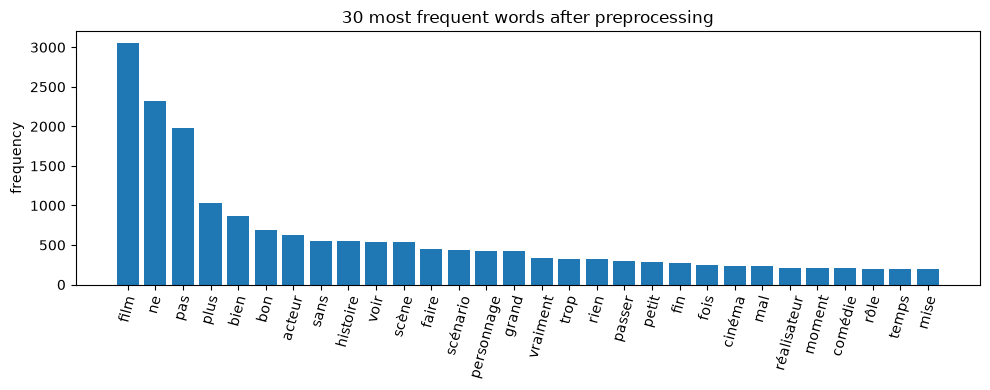

{'mauvais': 78, 'nul': None, 'excellent': 36, 'génial': 206, 'ennuyeux': 211}


In [20]:
counter = Counter(t for toks in tokens_prep for t in toks)
top30 = counter.most_common(30)

print(pd.DataFrame(top30, columns=["word", "count"]))

words, counts = zip(*top30)
plt.figure(figsize=(10, 4))
plt.bar(words, counts)
plt.xticks(rotation=75)
plt.ylabel("frequency")
plt.title("30 most frequent words after preprocessing")
plt.tight_layout()
plt.show()

rank = {w: i + 1 for i, (w, _) in enumerate(counter.most_common())}
print({w: rank.get(w) for w in ["mauvais", "nul", "excellent", "génial", "ennuyeux"]})

- **Cinema words dominate**: `film` is by far the most frequent word, and `acteur`, `histoire`, `scène`, `scénario`, `personnage`, `cinéma`, `réalisateur`, `comédie`, `rôle` are all in the top 30. Every review is about a film, so they appear in positive and negative reviews alike.
- They therefore carry **almost no sentiment information** and behave like **domain-specific stop words**. spaCy's generic list does not know about cinema, so they survive. A next step would be to add them to STOP or let TF-IDF down-weight them.
- **The negations we kept** (`ne`, `pas`, `plus`, `sans`, `rien`) rank very high, which confirms they are frequent and worth keeping.
- **Evaluative words** (`bien`, `bon`, `grand`, `mal`, `trop`) are present. Stronger polarity words such as `mauvais` and `excellent` rank lower (78th and 36th), `génial` and `ennuyeux` are around rank 200, and `nul` does not appear at all because it is a default stop word (see Q3.3). Yet these are the most useful words for classification.

### Q4.3 — Zipf's law

> Plot word frequency against rank, on a log-log scale. Does the curve roughly follow a straight line (Zipf’s law)?

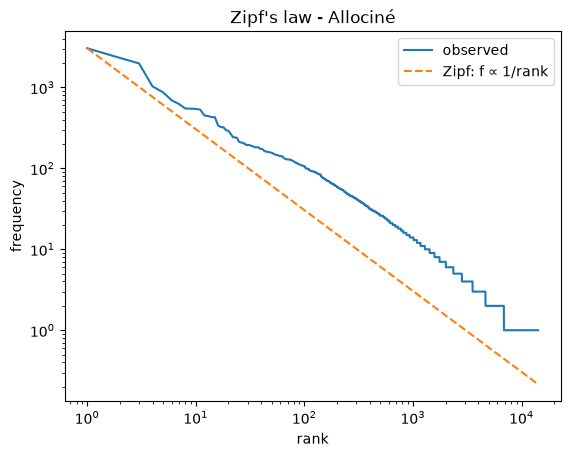

estimated slope: -0.82


In [21]:
corpus = tokens_prep   # list of token lists from Q4.1

freq = Counter(tok for doc in corpus for tok in doc)
values = sorted(freq.values(), reverse=True)
ranks = np.arange(1, len(values) + 1)

plt.loglog(ranks, values, label="observed")
# reference line: perfect Zipf, f = C / rank (slope -1), anchored on the top word
plt.loglog(ranks, values[0] / ranks, "--", label="Zipf: f ∝ 1/rank")
plt.xlabel("rank"); plt.ylabel("frequency")
plt.title("Zipf's law - Allociné")
plt.legend()
plt.show()

# estimated slope on the middle of the curve (ignores the head and the tail)
lo, hi = 10, 1000
slope = np.polyfit(np.log(ranks[lo:hi]), np.log(values[lo:hi]), 1)[0]
print(f"estimated slope: {slope:.2f}")

**Yes, roughly.** On the log-log scale the curve is close to a straight line over most of the ranks, which is Zipf's law (f ∝ 1/rank^s). The fitted slope between ranks 10 and 1,000 is about **−0.82**, a bit flatter than the ideal −1.

The deviations are expected:
- **Head:** we removed the most frequent words (stop words), so the top of the curve is flatter than in raw text, and `film` sits above the line because the corpus is about one topic.
- **Tail:** the curve ends in a long horizontal staircase, because thousands of words share the frequencies 1, 2, 3. With only 2,000 reviews the corpus is too small to fill in the rare words.

### Q4.4 — Hapaxes

> Compute the proportion of hapaxes (words seen only once). What consequence does this have for a future TF-IDF model?

In [22]:
hapaxes = [w for w, c in freq.items() if c == 1]

prop_types  = len(hapaxes) / len(freq)                    # share of the vocabulary
prop_tokens = len(hapaxes) / sum(freq.values())           # share of all tokens

print(f"hapaxes: {len(hapaxes)} / {len(freq)} types = {prop_types:.1%} of the vocabulary")
print(f"hapaxes: {prop_tokens:.1%} of all tokens")

hapaxes: 7321 / 14183 types = 51.6% of the vocabulary
hapaxes: 8.3% of all tokens


**About half of the vocabulary (51.6%) consists of hapaxes**, but they make up only 8.3% of the tokens.

Consequences for a TF-IDF model:
- **Large, sparse feature space.** Each hapax becomes a column that is non-zero in a single review: half of the columns carry almost no information.
- **Highest weights on the least reliable words.** IDF is largest for words that appear in only one document, so typos, names and rare words get the biggest weights.
- **Overfitting, no generalization.** A word seen once cannot be learned from, and it rarely appears again in new reviews.
- **Fix:** set a minimum document frequency (e.g. `TfidfVectorizer(min_df=2)` or higher). This removes about half of the vocabulary at little cost. Better cleaning (spelling correction, accent normalization) also turns some hapaxes into known words.

## Exercise 5 — Test and version

### Q5.1 — Module `preprocess.py`

> Copy clean_text, preprocess_text, NEGATIONS and STOP into a module preprocess.py.

In [23]:
%%writefile preprocess.py
"""Text preprocessing for French sentiment analysis (Allociné reviews).

Usage:
    from preprocess import clean_text, preprocess_text
"""
import re
import unicodedata

import spacy

__version__ = "1.0.0"

# Keep the parser and NER off: we only need tokenizer, tagger and lemmatizer.
nlp = spacy.load("fr_core_news_sm", disable=["parser", "ner"])

# Negation words are useful for sentiment: never treat them as stop words.
NEGATIONS = {"ne", "n'", "pas", "plus", "jamais", "rien", "sans", "aucun"}
STOP = nlp.Defaults.stop_words - NEGATIONS


def clean_text(text: str) -> str:
    """Remove noise (URLs, HTML, mentions, repeated chars, extra spaces)."""
    text = unicodedata.normalize("NFC", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)   # URLs
    text = re.sub(r"<[^>]+>", " ", text)                  # HTML tags
    text = re.sub(r"[@#]\w+", " ", text)                  # mentions / hashtags
    text = re.sub(r"([^\d\s])\1{2,}", r"\1", text)        # 3+ repeats -> 1
    text = re.sub(r"\s+", " ", text)                      # multiple spaces
    return text.strip()


def tokens_from_doc(doc, lemmas: bool = True, stop: bool = True) -> list[str]:
    """Turn an already-parsed spaCy Doc into a list of tokens."""
    out = []
    for tok in doc:
        if not (tok.is_alpha or tok.text == "n'"):
            continue
        w = tok.lemma_ if lemmas else tok.text
        if stop and (tok.text in STOP or w in STOP):
            continue
        out.append(w)
    return out


def normalize(text: str) -> str:
    """Clean, lowercase and use straight apostrophes (n’ -> n')."""
    return clean_text(text).lower().replace("’", "'")


def preprocess_text(text: str, lemmas: bool = True, stop: bool = True) -> list[str]:
    """Full pipeline for one text. For many texts use nlp.pipe + tokens_from_doc."""
    return tokens_from_doc(nlp(normalize(text)), lemmas, stop)

Overwriting preprocess.py


### Q5.2 — Tests with pytest

> Write test_preprocess.py with at least three tests, then run pytest.

In [24]:
%%writefile test_preprocess.py
from preprocess import clean_text, preprocess_text


def test_url_removed():
    assert "http" not in clean_text("Voir https://ex.fr/film")


def test_negation_kept():
    assert "pas" in preprocess_text("Ce n'est pas bon")


def test_repetitions():
    assert clean_text("Super!!!!!") == "Super!"


def test_html_mentions_hashtags_spaces():
    assert clean_text("<br />Trop   bien @marie #cinema<br />") == "Trop bien"


def test_numbers_not_collapsed():
    assert clean_text("Sorti en 2000") == "Sorti en 2000"


def test_curly_elision_negation_kept():
    # n’ (curly apostrophe) must be recognised as the negation ne
    assert "ne" in preprocess_text("Je n’aime pas ce film")


def test_stop_words_removed_and_lemmatized():
    assert preprocess_text("Les acteurs") == ["acteur"]


def test_options_off():
    assert preprocess_text("Les films", lemmas=False, stop=False) == ["les", "films"]

Overwriting test_preprocess.py


In [25]:
!python -m pytest -v test_preprocess.py

============================= test session starts =============================
platform win32 -- Python 3.12.12, pytest-9.2.0, pluggy-1.7.0 -- c:\Users\maxih\OneDrive\Skrivbord\skola\årskurs5\frankrike\nlp\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: c:\Users\maxih\OneDrive\Skrivbord\skola\årskurs5\frankrike\nlp
plugins: anyio-4.16.0, platformdirs-4.14.5
collecting ... collected 8 items

test_preprocess.py::test_url_removed PASSED                              [ 12%]
test_preprocess.py::test_negation_kept PASSED                            [ 25%]
test_preprocess.py::test_repetitions PASSED                              [ 37%]
test_preprocess.py::test_html_mentions_hashtags_spaces PASSED            [ 50%]
test_preprocess.py::test_numbers_not_collapsed PASSED                    [ 62%]
test_preprocess.py::test_curly_elision_negation_kept PASSED              [ 75%]
test_preprocess.py::test_stop_words_removed_and_lemmatized PASSED        [ 87%]
test_preprocess.py::test_options_of

### Q5.3 — Version the work

> Commit preprocess.py, the tests and the notebook to the pair’s repository.

```bash
git add preprocess.py test_preprocess.py TP1.ipynb
git commit -m "Lab 1: French preprocessing pipeline + tests"
git push
```

## Self-check

- [x] The negation is kept by `preprocess_text` (Q3.4, tests `test_negation_kept` and `test_curly_elision_negation_kept`).
- [x] The tests pass with pytest (Q5.2).
- [x] The Zipf plot is on a log-log scale and labeled (Q4.3).
- [x] The repository contains `preprocess.py`, the tests and the notebook (Q5.3).